# Start here: process one probe file and look at what came out

One raw probe file goes in; pictures of every particle, a verdict on each particle, and the
number of particles at each size, second by second, come out. No knowledge of Python or of
probe processing is assumed: run each cell in order (Shift+Enter) and read the text between
them.

The file used here is synthetic, a made-up 20-second flight (the Tutorial's `--dense` demo is a different, 5-second file) the package writes for you, because
real probe data cannot be shipped with it. Its output shows what the processing writes, not a
measurement of anything. A real flight is processed by the same command.

If you would rather not use a notebook, the same run is three terminal commands in
[`start_here/README.md`](../start_here/README.md).

**Before this:** nothing; this is the first notebook. **Next:** [02_quickstart](02_quickstart.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
import os
from pathlib import Path

# Find the repository root from wherever the notebook was started, and work from there.
def _is_root(p):
    has_project = (p / "pyproject.toml").is_file()
    return has_project and (p / "scripts").is_dir() and (p / "tests" / "data").is_dir()


_root = next((p for p in (Path.cwd(), *Path.cwd().parents) if _is_root(p)), None)
if _root is None:
    raise RuntimeError(
        f"Could not find the repository root above {Path.cwd()}. Start the notebook inside the "
        "repository. Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )
os.chdir(_root)

import subprocess
import sys

import netCDF4
import numpy as np
import xarray as xr

HERE = Path("examples/start_here")   # the settings file and the results folder
OUT = HERE / "output"
RAW = OUT / "base160101000000.2DS"

## Step 1: a file to process

A 2D-S probe records the shadow each cloud particle casts as it flies through a laser beam, and
writes those shadows to one raw file per flight. This cell writes a small synthetic one, plus a
record of the aircraft's airspeed, which the processing needs to turn counts into
concentrations.

In [2]:
OUT.mkdir(parents=True, exist_ok=True)
# The demo-flight tool draws particle sizes from a fixed list. Here we hand it a size
# population shaped like a real cloud: many small particles, a few large ones
# (an exponential in diameter, in 10 um diodes), drawn with a fixed seed.
from arrayprobe.tools import make_demo_flight as demo

rng = np.random.default_rng(2016)
diameters = np.clip(np.round(6 + rng.exponential(9, 600)), 6, 60).astype(int)
demo.DENSE_DISK_DIAMETERS = tuple(diameters)
demo.build_dense_demo_flight(RAW, n_seconds=20)
demo.write_demo_aircraft(RAW, n_seconds=20)
for name in ("base160101000000.2DS", "base160101000000.aircraft.cdf"):
    print(f"{name}: {(OUT / name).stat().st_size:,} bytes")

base160101000000.2DS: 164,560 bytes
base160101000000.aircraft.cdf: 1,036 bytes


## Step 2: run it

One command does the whole processing. Its settings are in
[`start_here/run.toml`](../start_here/run.toml), a text file with a comment on every line. In a
terminal, from the repository root, the command is:

```
.venv/Scripts/python.exe -m arrayprobe run examples/start_here/run.toml examples/start_here/output/base160101000000.2DS --yes
.venv/bin/python -m arrayprobe run examples/start_here/run.toml examples/start_here/output/base160101000000.2DS --yes
```

(the first line on Windows, the second on Linux or macOS). The next cell runs exactly that
command and shows the lines where each step finished.

In [3]:
done = subprocess.run([sys.executable, "-m", "arrayprobe", "run", str(HERE / "run.toml"), str(RAW),
                       "--yes"], check=True, capture_output=True, text=True)
steps = [line for line in done.stdout.splitlines() if " done " in line or "ALL DONE" in line]
print("\n".join(line.split("] ", 1)[-1].split(" (")[0] for line in steps))

  done    base160101000000.2DS               0 MB
ALL DONE in 0.0 min


## Step 3: what was written

Four files in `examples/start_here/output/` hold the results:

| File | What it holds |
|---|---|
| `base160101000000.H.nc` | the pictures: every particle's shadow, as the probe recorded it |
| `proc.base160101000000.H.nc` | one row per particle: its size, shape, and a verdict |
| `sd.base160101000000.H.nc` | one row per second and size range: how many particles there were |
| `base160101000000.combined.H.2DS.cdf` | the flight's final product, one file |

The other files beside them record how each step was run. The cells below look at the
results.

The next cell is setup for Figure 1 and draws nothing: it loads the plotting tools, reads the
first four records of pictures, and turns each colour the processing draws into a legend entry
in words.

In [4]:
# Setup for Figure 1: read the first 4 records and name every colour in plain words.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from arrayprobe import diagnostic_views as dv

plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "legend.fontsize": 10})

def unit_text(u):
    """'cm-4' -> cm$^{-4}$ for axis labels; the stored attribute is not changed."""
    base, _, power = str(u).partition("-")
    return f"{base}$^{{-{power}}}$" if power.isdigit() else str(u)

with (
    netCDF4.Dataset(OUT / "base160101000000.H.nc") as images,
    netCDF4.Dataset(OUT / "proc.base160101000000.H.nc") as proc,
):
    strip = dv.record_strip(images, proc, 1, 4)
img, palette = dv.strip_index_image(strip)
rgb = np.array(palette, dtype=np.uint8)[img]
n_diodes = strip.shadow.shape[2]
band = img.shape[0] // len(strip.records)          # rows per record: a tick band, then the diodes
role_names = {2: "particle boundary slice", 3: "shadow outside any particle"}
REJECT_WORDS = {"a": "aspect ratio too large", "t": "elongated, touching the edge",
                "p": "too few shadowed diodes", "s": "split image", "z": "zero area"}
HOLLOW_KEPT = {"0": "clean", "R": "reaccepted", **dict.fromkeys("Hhu", "flagged hollow")}
kept = sorted({p.reject for p in strip.particles if p.category(strip.colour_by) == "accepted"})
accepted_label = "accepted (" + ", ".join(sorted({f"{HOLLOW_KEPT[c]} '{c}'" for c in kept})) + ")"
names = {**role_names, **{5 + k: (accepted_label if c == "accepted"
                                  else "rejected: " + REJECT_WORDS.get(c.split()[-1], c))
                          for k, c in enumerate(strip.categories)}}
diodes = np.concatenate([img[k * band + band - n_diodes:(k + 1) * band] for k in range(4)])
handles = [Patch(facecolor=np.array(palette[i]) / 255, edgecolor="0.5", label=names[i])
           for i in sorted(names) if (diodes == i).any()]

This cell draws Figure 1. Each panel shows part of one record from the probe, one pixel per slice across and one diode up, coloured by what the processing decided about that particle's shadow.

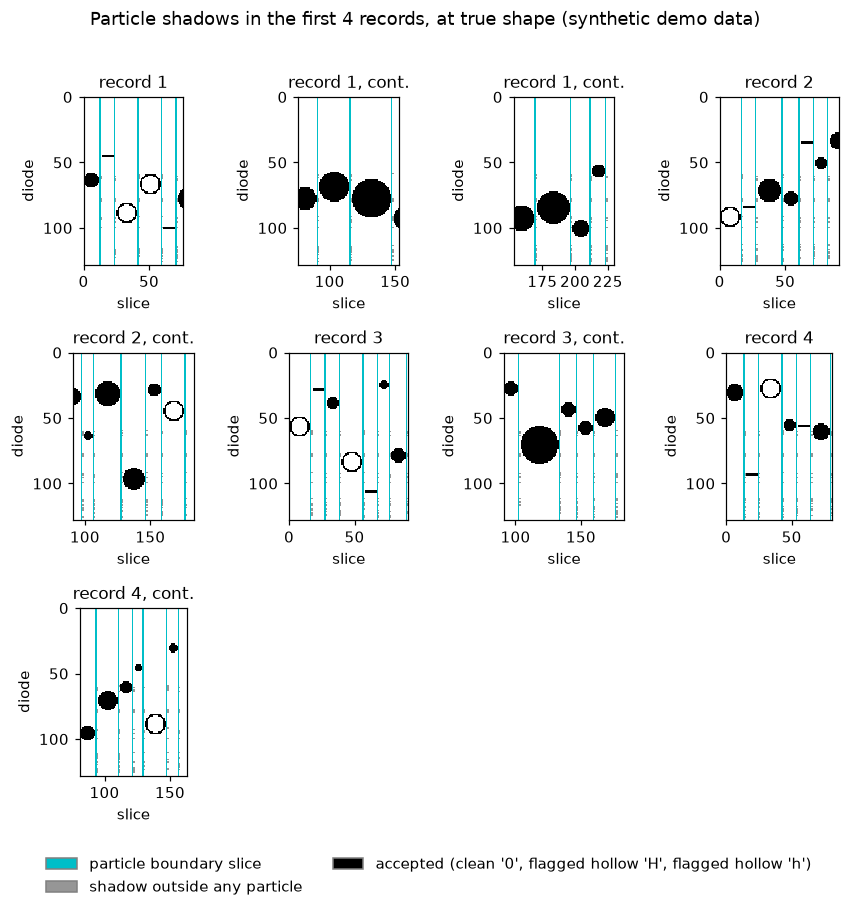

In [5]:
# Output 1: the pictures. Each panel is part of one record of the probe (a stretch of time),
# drawn at true shape: one pixel is one slice across and one diode up. Colour says what the
# processing decided about each particle's shadow.
WIDTH = 90                                         # slices per panel, so the panels fit the page
panels = []
for k in range(len(strip.records)):
    body = rgb[k * band + band - n_diodes:(k + 1) * band]
    used = np.flatnonzero((img[k * band + band - n_diodes:(k + 1) * band] > 1).any(axis=0))
    end = min(body.shape[1], used.max() + 6)       # crop the empty end of each record
    cuts = np.linspace(0, end, max(1, round(end / WIDTH)) + 1).astype(int)   # near-equal panels
    for part, (start, stop) in enumerate(zip(cuts[:-1], cuts[1:])):
        label = f"record {k + 1}" + (", cont." if part else "")
        panels.append((label, start, body[:, start:stop]))
ncol = 4
nrow = -(-len(panels) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(8, 2.4 * nrow + 1.1), squeeze=False)
for ax in axes.flat[len(panels):]:
    ax.axis("off")
for ax, (label, start, part) in zip(axes.flat, panels):
    ax.imshow(part, aspect="equal", interpolation="nearest",
              extent=(start, start + part.shape[1], n_diodes, 0))
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("slice", fontsize=10)
    ax.set_ylabel("diode", fontsize=10)
    ax.tick_params(labelsize=10)
fig.suptitle("Particle shadows in the first 4 records, at true shape (synthetic demo data)",
             fontsize=12)
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0.07, 1, 0.97))
plt.show()

*Figure 1. The first four records of the synthetic demo file, each split into panels of about 90 slices (a slice is one time step of the probe's scan) and cropped to the slices that hold particles, drawn at true shape (one pixel is one slice by one diode, a diode being one light sensor of the array), so round particles look round. The thin shapes one diode tall are tiny particles a single diode wide. Black shapes are accepted particles: the size distribution counts every particle UIOOPS accepts, including those it flags as hollow, so every particle drawn here is accepted; the legend names every other colour drawn.*

In [6]:
# Output 2: the verdict on each particle. "0" means accepted; any other letter is a flag the
# processing set. The legend is the one written inside the file itself.
with xr.open_dataset(OUT / "proc.base160101000000.H.nc", decode_times=False) as proc:
    codes = proc["image_auto_reject"].values
    legend = proc["image_auto_reject"].attrs["Description"]
print(f"{codes.size} particles seen")
for value, count in zip(*np.unique(codes, return_counts=True)):
    print(f"  code '{chr(value)}': {count} particles")
print("\nThe file's own legend:", legend)

240 particles seen
  code '0': 160 particles
  code 'H': 40 particles
  code 'h': 40 particles

The file's own legend: ASCII reject code ("0" or 48: accepted; "a" or 97: aspect ratio > 6; "t" or 116: aspect ratio > 5 + image touching edge; "p" or 112: < 25% shadowed diodes in rectangle encompassing particle; "h" or 104 or 72 or 117: hollow particle; "s" or 115: split image; "z" or 122: zero area image; "f" or 102: zero area image)


This cell draws the size distribution: how many particles were counted at each size, averaged over the flight, on logarithmic axes. The units are read from the file rather than assumed.

31 of 128 size ranges hold particles


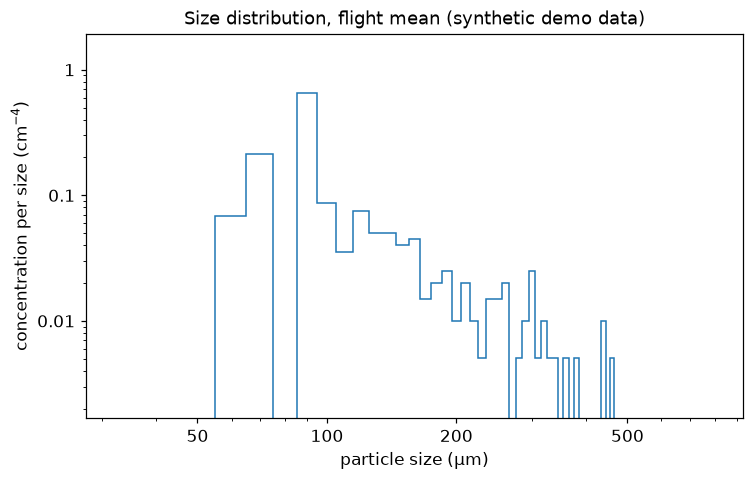

In [7]:
# Output 3: the size distribution -- how many particles there were at each size, averaged over
# the flight. The units are read from the file.
import matplotlib.ticker as mticker
with xr.open_dataset(OUT / "sd.base160101000000.H.nc", decode_times=False) as sd:
    size = sd["bin_mid"].values
    edges = np.append(sd["bin_min"].values, sd["bin_max"].values[-1])   # bin edges, for the steps
    conc = sd["conc_minR"].values.mean(axis=0)
    size_units, conc_units = sd["bin_mid"].attrs["units"], sd["conc_minR"].attrs["units"]
# Display only: sizes drawn in µm when the file stores mm; the data are unchanged.
scale = 1000.0 if size_units in ("mm", "millimeter") else 1.0
size_shown, edges_shown = size * scale, edges * scale
size_label = "µm" if scale == 1000.0 else size_units
held = conc > 0
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.stairs(np.where(held, conc, np.nan), edges_shown, color="tab:blue")   # one step per size range
ax.set_xscale("log")
ax.set_yscale("log")
lo, hi = edges_shown[:-1][held].min(), edges_shown[1:][held].max()
ax.set_xlim(lo / 2, hi * 2)                        # zoom to the sizes that hold particles
ax.xaxis.set_major_locator(mticker.FixedLocator([20, 50, 100, 200, 500, 1000, 2000]))
ax.set_ylim(conc[held].min() / 3, conc[held].max() * 3)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel(f"particle size ({size_label})")
ax.set_ylabel(f"concentration per size ({unit_text(conc_units)})")
ax.set_title("Size distribution, flight mean (synthetic demo data)")
fig.tight_layout()
plt.show()
print(f"{int((conc > 0).sum())} of {size.size} size ranges hold particles")

*Figure 2. Mean size distribution over the demo flight, zoomed to the size ranges that hold particles; each dot is one size range.*

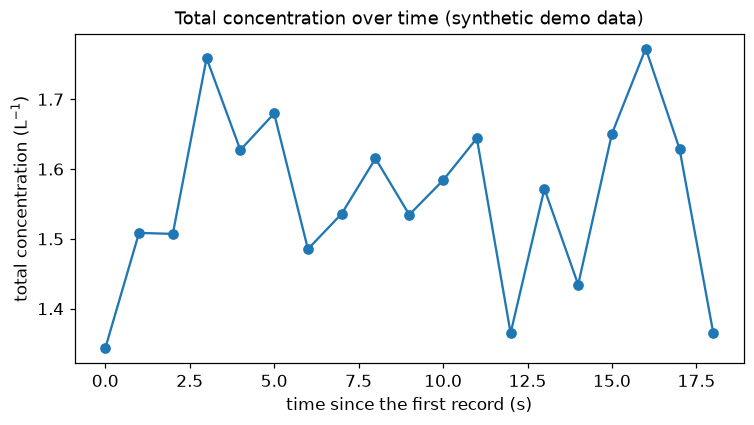

In [8]:
# Output 4: the total over time -- how many particles per volume of air, second by second.
with xr.open_dataset(OUT / "sd.base160101000000.H.nc", decode_times=False) as sd:
    hhmmss = sd["time"].values.astype(int)
    total = sd["n"].values
    total_units = sd["n"].attrs["units"]
seconds = hhmmss // 10000 * 3600 + hhmmss // 100 % 100 * 60 + hhmmss % 100
fig, ax = plt.subplots(figsize=(7, 4))
# Display only: cm-3 drawn as L-1 (x 1000), the usual unit for these particle sizes.
shown, shown_units = (total * 1000.0, "L$^{-1}$") if total_units == "cm-3" else (total, unit_text(total_units))
ax.plot(seconds - seconds[0], shown, marker="o")
ax.set_xlabel("time since the first record (s)")
ax.set_ylabel(f"total concentration ({shown_units})")
ax.set_title("Total concentration over time (synthetic demo data)")
fig.tight_layout()
plt.show()

*Figure 3. Total particle concentration, one value per second of the demo flight.*

## Step 4: your own file

Copy `start_here/run.toml`, then change what describes your data:

1. **The probe and its settings.** The demo's settings (`preset = "DEMO_2DS_H"`) fit only the
   synthetic file. Your own flight needs a presets file naming the probe (`2DS` or `HVPS`), its
   channel (`H` or `V`), a project name (it selects UIOOPS's per-project settings), and the flight's mean air pressure (`pres_pa`, in Pa)
   and temperature (`temp_c`, in °C), which come from the aircraft's own data. Put them in a
   TOML file of `[[campaign]]` tables, name that file in `run.toml`'s `[run]` table as
   `presets = "my_presets.toml"` (a path relative to `run.toml`), and set `preset` to the preset
   it defines; the same `arrayprobe run` command then reads it. The fields a preset takes are in
   [`06-configuration.md`](../../docs/06-configuration.md).
2. **The airspeed.** Either make an airspeed file from the aircraft's data with
   `arrayprobe make-tas-file` and name it in `tas_file`, or use the airspeed the probe records
   itself (`[tas] source = "probe"`). [`02_airspeed_and_stuck_airspeed.ipynb`](../5_data_quality/02_airspeed_and_stuck_airspeed.ipynb) explains the
   choice.
3. **The raw file.** Name your own file in place of the demo's on the command line.

For CIP or PIP, see [the CIP page](../../docs/36-probe-cip.md).

Next: [`02_quickstart.ipynb`](02_quickstart.ipynb); [`06_read_products.ipynb`](06_read_products.ipynb) explains every variable in these files.